In [542]:
import pandas as pd
from scipy.stats import mannwhitneyu
from pathlib import Path
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np
from scipy.stats import chi2_contingency
import seaborn as sns

In [543]:
gateways = pd.read_csv('180/gateways.csv', sep=';', on_bad_lines='warn')
readings = pd.read_csv('180/readings.csv', sep = r"\t", on_bad_lines='warn', engine='python')
units = pd.read_csv('180/units.csv', on_bad_lines='warn')

original_gateways = gateways.copy()
original_readings = readings.copy()
original_units = units.copy()

In [544]:
display(gateways.head())
display(readings.head())
display(units.head())

,depot_id,vendor,modelHardware,id_unit,technician,Lon,gatewayId,address_mac,installDate,ipv4,signal_dbm,lastSeen,Lat,firmware_version
0,52,Pinho Lopes Lda.,GWX-200,1739.0,Irina Leal,-6.34286,GW-00000,c0:f5:84:f8:08:41,2024/06/06,188.32.87.90,-65.2,"10/10/2024, 00:00:00",40.57291,v2.7.0
1,113,Christoph GmbH,GWX-100,103.0,Carminho Fonseca,-6.61695,GW-00001,30:db:d5:75:e1:e2,"12/10/2021, 00:00:00",132.117.107.236,-78.7,2024-04-26,39.47290,v1.2.5
2,112,Rädel Löwer AG,GWX-100,13.0,Dr. Marc Robinson,-7.48817,GW-00002,cd:c6:2c:7f:93:2e,2024-04-21,114.142.159.228,-74.9,04 Nov 2024,39.16074,v1.2.5
3,104,Roy and Sons,NODE-9,1344.0,Ryan Rios,-8.59568,GW-00003,d5:03:c8:7c:50:b4,"12/03/2022, 00:00:00",164.198.143.169,-68.3,25 Jan 2025,39.01984,v1.2.5
4,36,Christoph GmbH,GWX-100,1324.0,César da Neto,-9.18714,GW-00004,93:41:75:8f:f1:d5,15 May 2018,65.233.19.254,-52.2,2024-08-06,39.47786,v1.2.5


,id_unit,cycleTs,currentMotor,dpFilter,oilTemperature,reservoirPressure,pressureOil,rms_vibration,flowmeter,humidity_intake,noiseAmbient,dischargeDewpoint,Failure
0,U00193,"08/27/2023, 06:29:00",4.05968,18.69811,64.86904,8.81915,3.75608,2.42950,27.70488,71.41778,71.88633,15.83173,0
1,U00757,2023/11/13,2.36328,49.17312,51.49558,8.07426,3.30342,4.46937,26.57501,65.59907,69.74589,11.00633,1
2,U01997,2023-11-26,7.33857,11.09040,48.07975,9.78198,4.56246,6.87273,32.19223,79.35666,78.22245,6.20960,0
3,U01633,2023-02-22,5.69969,19.58462,73.09699,9.65227,4.35662,NaN,27.33163,62.12112,72.77351,5.18222,1
4,U00467,"01/23/2023, 03:45:00",3.92084,22.86953,64.31103,8.68221,3.62936,6.36960,29.46377,43.40507,73.24571,6.12806,0


,codeFleet,depot_id,hours_service,model_code,line_code,manufacturer,overhaulLast,id_unit,year_commission,region_install,serial_number,ownerOperator,duty_class
0,FA,105,20874.1,XC-7,L6,"Rivers, Welch and Hood","05/06/2023, 00:00:00",1,2019,Christinehaven,AJ-0056-27354,Huhn KGaA,3
1,FA,37,6896.4,XC-7,L4,Walker Ltd,2024-01-15,2,2023,Zerbst,ED-7134-75911,Rädel Löwer AG,heavy
2,FE,36,8193.9,APU-12,L4,Schenk GmbH,2023/01/19,3,2022,Guimarães,AT-0639-19922,Macedo Faria e Filhos,1
3,FB,102,18235.4,APU-20,L6,Silva,2024-03-14,4,2019,Lake Amy,JW-3703-50512,Reinhardt,3
4,FB,11,11350.3,XC-7,L5,Huhn KGaA,2019-05-07,5,2021,Fiães,UC-0462-35464,Leal Freitas S/A,1


In [545]:
display(gateways.info())
display(readings.info())
display(units.info())


<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   depot_id          16000 non-null  int64  
 1   vendor            16000 non-null  str    
 2   modelHardware     16000 non-null  str    
 3   id_unit           2000 non-null   float64
 4   technician        16000 non-null  str    
 5   Lon               16000 non-null  float64
 6   gatewayId         16000 non-null  str    
 7   address_mac       16000 non-null  str    
 8   installDate       16000 non-null  str    
 9   ipv4              16000 non-null  str    
 10  signal_dbm        16000 non-null  float64
 11  lastSeen          16000 non-null  str    
 12  Lat               16000 non-null  float64
 13  firmware_version  16000 non-null  str    
dtypes: float64(4), int64(1), str(9)
memory usage: 1.7 MB


None

<class 'pandas.DataFrame'>
RangeIndex: 15572 entries, 0 to 15571
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_unit            15572 non-null  str    
 1   cycleTs            15572 non-null  str    
 2   currentMotor       15572 non-null  float64
 3   dpFilter           14910 non-null  float64
 4   oilTemperature     15572 non-null  float64
 5   reservoirPressure  15572 non-null  float64
 6   pressureOil        15572 non-null  float64
 7   rms_vibration      14950 non-null  float64
 8   flowmeter          15572 non-null  float64
 9   humidity_intake    14780 non-null  float64
 10  noiseAmbient       15572 non-null  float64
 11  dischargeDewpoint  15572 non-null  float64
 12  Failure            15572 non-null  int64  
dtypes: float64(10), int64(1), str(2)
memory usage: 1.5 MB


None

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   codeFleet        2000 non-null   str    
 1   depot_id         2000 non-null   int64  
 2   hours_service    1900 non-null   float64
 3   model_code       2000 non-null   str    
 4   line_code        2000 non-null   str    
 5   manufacturer     2000 non-null   str    
 6   overhaulLast     2000 non-null   str    
 7   id_unit          2000 non-null   int64  
 8   year_commission  2000 non-null   int64  
 9   region_install   2000 non-null   str    
 10  serial_number    2000 non-null   str    
 11  ownerOperator    2000 non-null   str    
 12  duty_class       2000 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 203.3 KB


None

In [546]:
display(gateways.describe())
display(readings.describe())
display(units.describe())

,depot_id,id_unit,Lon,signal_dbm,Lat
count,16000.000000,2000.000000,16000.000000,16000.000000,16000.000000
mean,58.812063,1000.500000,-7.747075,-70.009619,40.157236
std,34.701699,577.494589,0.902379,9.933242,0.889437
min,0.000000,1.000000,-9.299830,-106.100000,38.600100
25%,28.000000,500.750000,-8.534870,-76.700000,39.390237
50%,59.000000,1000.500000,-7.737640,-70.200000,40.168405
75%,89.000000,1500.250000,-6.963240,-63.100000,40.923405
max,119.000000,2000.000000,-6.200030,-40.000000,41.699630


,currentMotor,dpFilter,oilTemperature,reservoirPressure,pressureOil,rms_vibration,flowmeter,humidity_intake,noiseAmbient,dischargeDewpoint,Failure
count,15572.000000,14910.000000,15572.000000,15572.000000,15572.000000,14950.000000,15572.000000,14780.000000,15572.000000,15572.000000,15572.000000
mean,5.296595,24.119032,51.744591,8.692845,3.692293,3.061109,28.028240,52.308947,74.990066,8.048645,0.117968
std,3.273052,11.502224,59.647429,0.598296,0.561880,1.628904,3.956733,24.458946,5.994324,3.502732,0.322581
min,0.266600,7.448490,-999.000000,6.500000,1.500000,0.500000,15.000000,10.005000,55.000000,-4.322190,0.000000
25%,3.743080,16.329075,46.756825,8.285735,3.311948,1.925193,25.348402,31.194165,70.977465,5.666780,0.000000
50%,5.087180,21.389575,54.967085,8.691360,3.688170,2.709255,28.029065,52.068300,74.961685,8.013085,0.000000
75%,6.663353,28.541063,63.158803,9.096332,4.070700,3.774242,30.713195,73.350480,79.073712,10.414853,0.000000
max,99.000000,120.000000,95.000000,10.500000,5.775210,14.000000,40.000000,94.997260,95.000000,22.421020,1.000000


,depot_id,hours_service,id_unit,year_commission
count,2000.000000,1900.000000,2000.000000,2000.000000
mean,56.210500,14099.588263,1000.500000,2020.456000
std,34.516473,8596.450754,577.494589,2.475506
min,0.000000,1499.700000,1.000000,2012.000000
25%,26.000000,7832.825000,500.750000,2019.000000
50%,54.000000,11942.750000,1000.500000,2021.000000
75%,86.000000,18015.800000,1500.250000,2022.000000
max,119.000000,45000.000000,2000.000000,2024.000000


## 1.2 A - Data problems and initial cleaning

### Machine identifiers and relationships

In [547]:
readings["id_unit"] = readings["id_unit"].astype("string").str.removeprefix("U").astype("Int64")
gateways["id_unit"] = gateways["id_unit"].astype("Int64")
units["id_unit"] = units["id_unit"].astype("Int64")


**Check unit coverage**

In [548]:
tables = {"units": units, "gateways": gateways, "readings": readings}

display(pd.DataFrame({
    name: {
        "rows": len(table),
        "unique_unit_ids": table["id_unit"].nunique(),
        "missing_unit_ids": table["id_unit"].isna().sum(),
        "duplicate_unit_ids": table["id_unit"].dropna().duplicated().sum(),
    }
    for name, table in tables.items()
}).T)

unit_ids = set(units["id_unit"].dropna())
gateway_unit_ids = set(gateways["id_unit"].dropna())
reading_unit_ids = set(readings["id_unit"].dropna())

orphan_readings = readings.loc[~readings["id_unit"].isin(unit_ids)].copy()
print(f"Assigned gateway IDs absent from units: {len(gateway_unit_ids - unit_ids)}")
print(f"Units without gateways: {len(unit_ids - gateway_unit_ids)}")
print(f"Units without readings: {len(unit_ids - reading_unit_ids)}")
print(f"Orphan readings: {len(orphan_readings)} rows, {orphan_readings['id_unit'].nunique()} distinct IDs")

print(f"Mean readings per observed ID, including orphan IDs: {readings.groupby('id_unit').size().mean():.2f}")
registered_readings = readings.loc[readings["id_unit"].isin(unit_ids)]
print(f"Mean readings per registered unit: {registered_readings.groupby('id_unit').size().mean():.2f}")


,rows,unique_unit_ids,missing_unit_ids,duplicate_unit_ids
units,2000,2000,0,0
gateways,16000,2000,14000,0
readings,15572,2134,0,13438


Assigned gateway IDs absent from units: 0
Units without gateways: 0
Units without readings: 0
Orphan readings: 162 rows, 134 distinct IDs
Mean readings per observed ID, including orphan IDs: 7.30
Mean readings per registered unit: 7.71


### Date formats

In [549]:
date_columns = {
    "readings.cycleTs": readings["cycleTs"],
    "gateways.installDate": gateways["installDate"],
    "gateways.lastSeen": gateways["lastSeen"],
    "units.overhaulLast": units["overhaulLast"],
}

all_dates = pd.concat(
    [
        dates.to_frame(name="date").assign(source=name, source_row = dates.index)
        for name, dates in date_columns.items()
    ],
    ignore_index=True,
)

all_dates['pattern'] = all_dates["date"]
all_dates['pattern'] = all_dates["pattern"].str.replace(r"[A-Za-z]", "S", regex=True)
all_dates['pattern'] = all_dates["pattern"].str.replace(r"\d", "D", regex=True)

patterns_grouped = all_dates.groupby('pattern').size().reset_index(name='count')
display(patterns_grouped.sort_values(by='count', ascending=False).reset_index(drop=True))

for group in patterns_grouped['pattern']:
    sample = all_dates.loc[all_dates['pattern'] == group, 'date']
    print(f"Pattern: {group}, Count: {len(sample)}")
    display(sample.head(5).to_frame(name='date').reset_index(drop=True))

,pattern,count
0,DD SSS DDDD,12465
1,DDDD/DD/DD,12429
2,"DD/DD/DDDD, DD:DD:DD",12355
3,DDDD-DD-DD,12323


Pattern: DD SSS DDDD, Count: 12465


,date
0,24 May 2023
1,09 Oct 2023
2,02 May 2023
3,28 Feb 2023
4,20 Jun 2023


Pattern: DD/DD/DDDD, DD:DD:DD, Count: 12355


,date
0,"08/27/2023, 06:29:00"
1,"01/23/2023, 03:45:00"
2,"02/24/2023, 11:59:00"
3,"04/01/2023, 01:23:00"
4,"12/08/2023, 03:18:00"


Pattern: DDDD-DD-DD, Count: 12323


,date
0,2023-11-26
1,2023-02-22
2,2023-01-05
3,2023-05-12
4,2023-01-09


Pattern: DDDD/DD/DD, Count: 12429


,date
0,2023/11/13
1,2023/05/23
2,2023/12/21
3,2023/10/31
4,2023/01/12


The four date formats require explicit parsing to avoid ambiguous month/day interpretation.

In [550]:
formats = {
    "DDDD-DD-DD": "%Y-%m-%d",
    "DDDD/DD/DD": "%Y/%m/%d",
    "DD/DD/DDDD, DD:DD:DD": "%m/%d/%Y, %H:%M:%S",
    "DD SSS DDDD": "%d %b %Y",
}

all_dates["parsed_date"] = pd.Series(pd.NaT, index=all_dates.index, dtype="datetime64[ns]")

for pattern, date_format in formats.items():
    mask = all_dates["pattern"].eq(pattern)
    all_dates.loc[mask, "parsed_date"] = pd.to_datetime(
        all_dates.loc[mask, "date"],
        format=date_format,
        errors="coerce",
    )

unknown_format = all_dates["date"].notna() & ~all_dates["pattern"].isin(formats)
all_dates.loc[unknown_format, "parsed_date"] = pd.to_datetime(
    all_dates.loc[unknown_format, "date"],
    format="mixed",
    dayfirst=False,
    errors="coerce",
)

failed = all_dates["date"].notna() & all_dates["parsed_date"].isna()
print("Parsing failures:", failed.sum())
if failed.any():
    display(all_dates.loc[failed, ["source", "date", "pattern"]])

display(all_dates.head(5))

Parsing failures: 0


,date,source,source_row,pattern,parsed_date
0,"08/27/2023, 06:29:00",readings.cycleTs,0,"DD/DD/DDDD, DD:DD:DD",2023-08-27 06:29:00
1,2023/11/13,readings.cycleTs,1,DDDD/DD/DD,2023-11-13 00:00:00
2,2023-11-26,readings.cycleTs,2,DDDD-DD-DD,2023-11-26 00:00:00
3,2023-02-22,readings.cycleTs,3,DDDD-DD-DD,2023-02-22 00:00:00
4,"01/23/2023, 03:45:00",readings.cycleTs,4,"DD/DD/DDDD, DD:DD:DD",2023-01-23 03:45:00


In [551]:
source_groups = all_dates.groupby("source")
for source, group in source_groups:
    df_name, col_name = source.split(".")
    df = tables[df_name]
    df[col_name] = group.set_index("source_row")["parsed_date"]

for key in date_columns.keys():
    df_name, col_name = key.split(".")
    df = tables[df_name]
    print(f"{key} is now {df[col_name].dtype}")

readings.cycleTs is now datetime64[ns]
gateways.installDate is now datetime64[ns]
gateways.lastSeen is now datetime64[ns]
units.overhaulLast is now datetime64[ns]


Date-only values become midnight timestamps; their original measurement time remains unknown.

### Duty-class labels

In [552]:
print(units['duty_class'].dtype)
display(units['duty_class'].value_counts())

classes = {
    1: ['L', '1', 'light', 'lig'],
    2: ['N', '2', 'medium', 'med', 'normal', 'nor'],
    3: ['H', '3', 'heavy', 'hea'],
}

units['duty_class'] = units['duty_class'].astype(str).str.strip().replace(
    {alias: class_id for class_id, aliases in classes.items() for alias in aliases}
)
units["duty_class"] = units["duty_class"].astype("Int64")

display(units['duty_class'].value_counts())

str


duty_class
L           253
1           250
light       217
N           170
heavy       163
3           161
med         160
normal      155
2           142
H           138
 L           31
 med         25
 1           24
 heavy       23
 light       22
 N           17
 H           14
 normal      14
 3           12
 2            9
Name: count, dtype: int64

duty_class
1    797
2    692
3    511
Name: count, dtype: Int64

### Duplicate records

In [553]:
print("Duplicates in readings:", readings.duplicated().sum())
print("Duplicates in gateways:", gateways.duplicated().sum())
print("Duplicates in units:", units.duplicated().sum())

Duplicates in readings: 230
Duplicates in gateways: 0
Duplicates in units: 0


In [554]:
by = readings.columns.drop("Failure").tolist()
readings_duplicates = readings.duplicated(keep=False, subset=by)
readings[readings_duplicates].sort_values(by=["id_unit", "cycleTs"]).head()

,id_unit,cycleTs,currentMotor,dpFilter,oilTemperature,reservoirPressure,pressureOil,rms_vibration,flowmeter,humidity_intake,noiseAmbient,dischargeDewpoint,Failure
4355,7,2023-02-16,3.80106,28.66523,55.83890,8.53011,3.45003,3.91290,26.67650,89.62810,76.52630,8.26298,0
15344,7,2023-02-16,3.80106,28.66523,55.83890,8.53011,3.45003,3.91290,26.67650,89.62810,76.52630,8.26298,0
135,18,2023-05-23,5.88054,NaN,47.30147,8.44777,3.64306,6.40298,29.80144,22.71621,78.76249,6.40166,1
15494,18,2023-05-23,5.88054,NaN,47.30147,8.44777,3.64306,6.40298,29.80144,22.71621,78.76249,6.40166,1
10621,25,2023-01-03,3.43932,24.73694,68.39848,9.26754,4.65420,2.62269,28.39953,92.33999,78.47459,5.09118,0


In [555]:
group_duplicates = readings[readings_duplicates].groupby(by, dropna=False)
print("Groups of duplicate readings:", len(group_duplicates))
failed = False
for group, df in group_duplicates:
    for row in df.itertuples():
        if row.Failure != df.iloc[0].Failure:
            print(f"Duplicate readings with different Failure values for id_unit {row.id_unit} at cycleTs {row.cycleTs}:")
            display(df)
            failed = True
            break

if not failed:
    print("All duplicate readings have the same Failure value")
else:
    raise RuntimeError("Duplicate readings with different Failure values found")

dropped = readings.drop_duplicates()
difference = len(readings) - len(dropped)
readings = dropped
tables["readings"] = readings
print(f"Dropped {difference} duplicate readings, new length: {len(readings)}")

Groups of duplicate readings: 230
All duplicate readings have the same Failure value
Dropped 230 duplicate readings, new length: 15342


Exclude records without a usable unit link

In [556]:
without_orphans = readings.drop(orphan_readings.index)
difference = len(readings) - len(without_orphans)
readings = without_orphans
tables["readings"] = readings
print(f"Dropped {difference} orphan readings, new length: {len(without_orphans)}")

Dropped 162 orphan readings, new length: 15180


In [557]:
display(gateways.isna().sum())
gateways = gateways.dropna()
difference = len(tables["gateways"]) - len(gateways)
tables["gateways"] = gateways
print("Dropped reduntant rows with missing values in gateways:", difference, "new length:", len(gateways))

depot_id                0
vendor                  0
modelHardware           0
id_unit             14000
technician              0
Lon                     0
gatewayId               0
address_mac             0
installDate             0
ipv4                    0
signal_dbm              0
lastSeen                0
Lat                     0
firmware_version        0
dtype: int64

Dropped reduntant rows with missing values in gateways: 14000 new length: 2000


### Missing operating hours

In [558]:
display(units.isna().sum())
display(units['hours_service'].head())
display(units['hours_service'].describe())


codeFleet            0
depot_id             0
hours_service      100
model_code           0
line_code            0
manufacturer         0
overhaulLast         0
id_unit              0
year_commission      0
region_install       0
serial_number        0
ownerOperator        0
duty_class           0
dtype: int64

0    20874.1
1     6896.4
2     8193.9
3    18235.4
4    11350.3
Name: hours_service, dtype: float64

count     1900.000000
mean     14099.588263
std       8596.450754
min       1499.700000
25%       7832.825000
50%      11942.750000
75%      18015.800000
max      45000.000000
Name: hours_service, dtype: float64

In [559]:
failure_rate_with_hours = readings.loc[readings['id_unit'].isin(units.loc[units['hours_service'].notna(), 'id_unit']), 'Failure'].mean()
failure_rate_without_hours = readings.loc[readings['id_unit'].isin(units.loc[units['hours_service'].isna(), 'id_unit']), 'Failure'].mean()
print(f"Failure rate with hours_service: {failure_rate_with_hours:.2%}")
print(f"Failure rate without hours_service: {failure_rate_without_hours:.2%}")

Failure rate with hours_service: 11.77%
Failure rate without hours_service: 11.89%


Correlation between hours_service and year_commission: -0.993216564997451


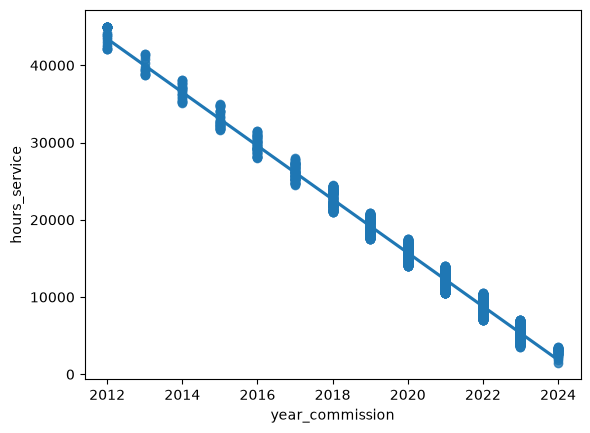

In [560]:
print("Correlation between hours_service and year_commission:", units['hours_service'].corr(units['year_commission']))

sns.regplot(
    data=units,
    x="year_commission",
    y="hours_service",
)
plt.show()

The strong relationship with commissioning year (r = -0.993) supports year-specific medians for missing operating hours.

In [561]:
year_medians = units.groupby("year_commission")["hours_service"].median()
units["hours_service"] = units["hours_service"].fillna(units["year_commission"].map(year_medians))
print("Remaining missing hours:", units["hours_service"].isna().sum())

Remaining missing hours: 0


### Missing sensor measurements

In [562]:
display(readings.isna().sum())
print(f"Rows with at least one NaN value: {readings.isna().any(axis=1).sum()}")

print(f"Failure rate including NaN: {readings['Failure'].mean():.2%}")
print(f"Failure rate excluding NaN: {readings.dropna()['Failure'].mean():.2%}")

nan_dict = readings.isna().sum().to_dict()

for col_name, nan_count in nan_dict.items():
    if nan_count > 0:
        print(f"Failure when Non-NaN {col_name}: {readings.loc[readings[col_name].notna(), 'Failure'].mean():.2%}")
        print(f"Failure when NaN {col_name}: {readings.loc[readings[col_name].isna(), 'Failure'].mean():.2%}")

id_unit                0
cycleTs                0
currentMotor           0
dpFilter             640
oilTemperature         0
reservoirPressure      0
pressureOil            0
rms_vibration        609
flowmeter              0
humidity_intake      769
noiseAmbient           0
dischargeDewpoint      0
Failure                0
dtype: int64

Rows with at least one NaN value: 1883
Failure rate including NaN: 11.78%
Failure rate excluding NaN: 8.39%
Failure when Non-NaN dpFilter: 9.88%
Failure when NaN dpFilter: 54.84%
Failure when Non-NaN rms_vibration: 10.03%
Failure when NaN rms_vibration: 53.69%
Failure when Non-NaN humidity_intake: 11.72%
Failure when NaN humidity_intake: 12.87%


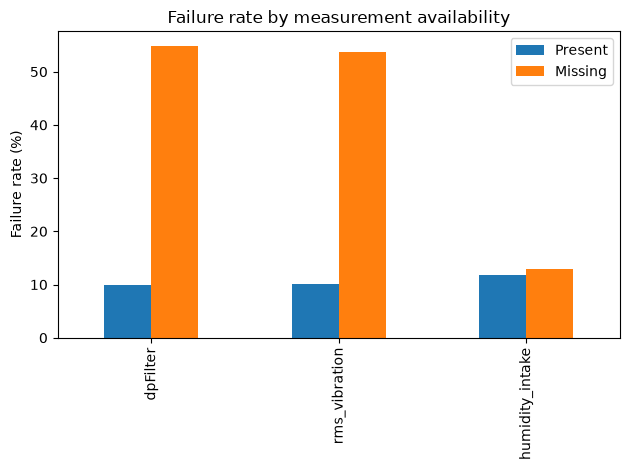

In [563]:
missing = readings.isna().sum()
missing = missing[missing > 0]
rates = {}

for column in missing.index:
    mask = readings[column].isna()
    rates[column] = [
        readings.loc[~mask, "Failure"].mean(),
        readings.loc[mask, "Failure"].mean(),
    ]

rates = pd.DataFrame(rates, index=["Present", "Missing"]).T * 100

rates.plot.bar(
    ylabel="Failure rate (%)",
    title="Failure rate by measurement availability",
)
plt.tight_layout()
plt.show()

Missing filter and vibration measurements are associated with higher failure rates.

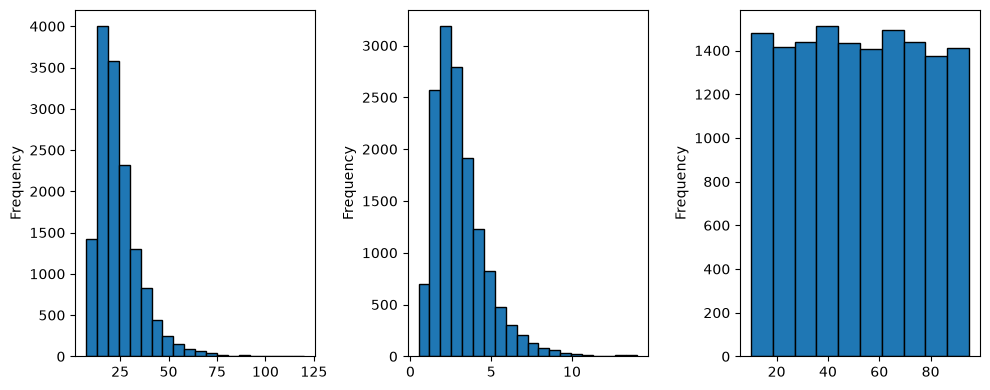

,dpFilter,rms_vibration,humidity_intake
count,14540.000000,14571.000000,14411.000000
mean,24.148033,3.063343,52.250240
std,11.529075,1.632727,24.438565
min,7.448490,0.500000,10.005000
25%,16.336648,1.925295,31.178215
50%,21.421300,2.709670,52.003580
75%,28.591145,3.774755,73.235935
max,120.000000,14.000000,94.997260


In [564]:
fig, ax = plt.subplots(1, 3, figsize=(10, 4))
readings['dpFilter'].plot.hist(bins=20, edgecolor='black', ax=ax[0])
readings['rms_vibration'].plot.hist(bins=20, edgecolor='black', ax=ax[1])
readings['humidity_intake'].plot.hist(bins=10, edgecolor='black', ax=ax[2])
plt.tight_layout()
plt.show()
display(readings[['dpFilter', 'rms_vibration', 'humidity_intake']].describe())

Use medians to reduce the influence of high values in the skewed filter and vibration distributions.

In [565]:
col_names = ['dpFilter', 'rms_vibration', 'humidity_intake']
for col in col_names:
    indicator = col + "_present"
    if indicator not in readings.columns:
        readings[indicator] = readings[col].notna()
    readings[col] = readings[col].fillna(readings[col].median())

print(f"Is there any NaN value in readings? {(readings.isna().sum() != 0).any()}")

Is there any NaN value in readings? False


,currentMotor,dpFilter,oilTemperature,reservoirPressure,pressureOil,rms_vibration,flowmeter,humidity_intake,noiseAmbient,dischargeDewpoint
count,15180.000000,15180.000000,15180.000000,15180.000000,15180.000000,15180.000000,15180.000000,15180.000000,15180.000000,15180.000000
mean,5.299512,24.033072,51.726227,8.694380,3.693563,3.049155,28.022353,52.237744,75.002971,8.045514
std,3.301838,11.296703,59.774835,0.598210,0.561271,1.601144,3.954876,23.811527,5.985740,3.507001
min,0.266600,7.448490,-999.000000,6.500000,1.500000,0.500000,15.000000,10.005000,55.000000,-4.322190
25%,3.743333,16.579738,46.756825,8.287865,3.313613,1.955258,25.342372,32.306562,70.987453,5.655123
50%,5.088230,21.421300,54.960995,8.693035,3.689560,2.709670,28.018050,52.003580,74.979985,8.006355
75%,6.667892,28.156025,63.158803,9.097970,4.071030,3.721132,30.707367,72.065930,79.077955,10.411972
max,99.000000,120.000000,95.000000,10.500000,5.775210,14.000000,40.000000,94.997260,95.000000,22.421020


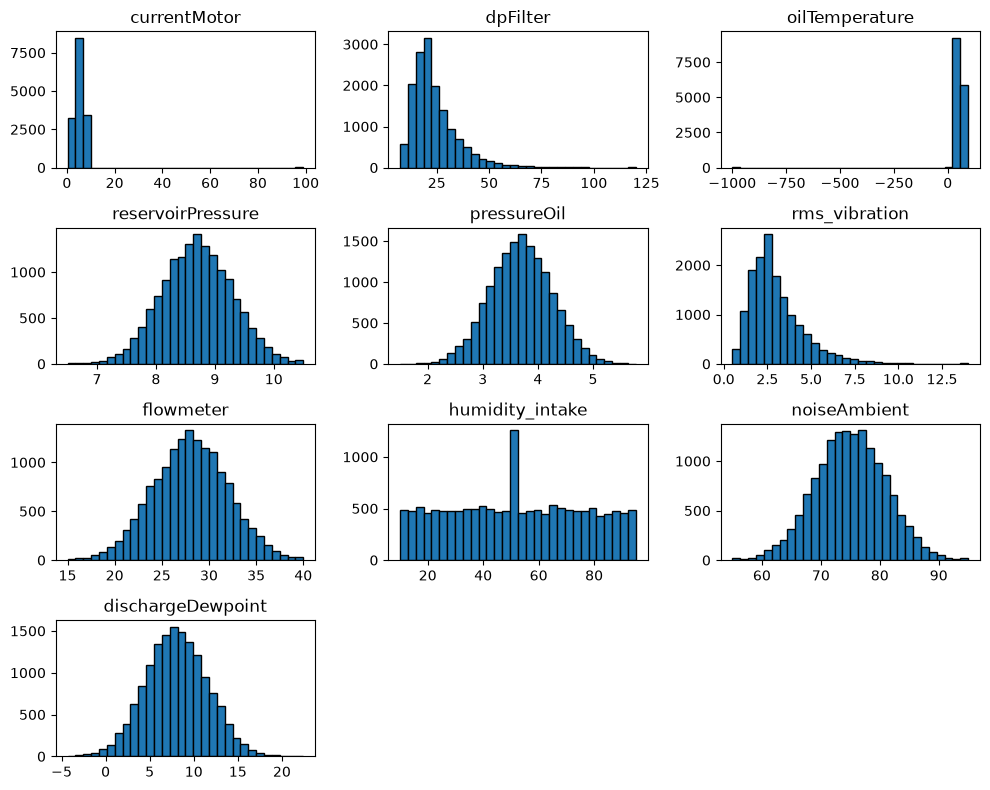

In [566]:
excluded = readings.drop(['id_unit', 'Failure', 'cycleTs'], axis=1)
display(excluded.describe())

_ = excluded.hist(bins=30, edgecolor='black', figsize=(10, 8), grid=False)
plt.tight_layout()
plt.show()

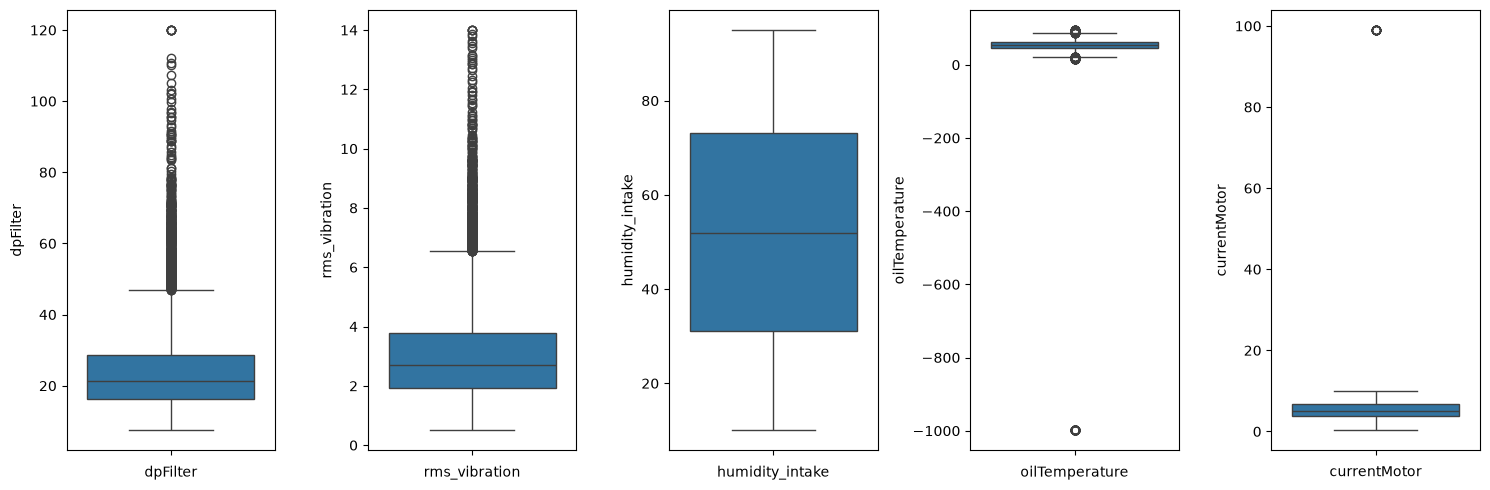

In [567]:
col_names = ['dpFilter', 'rms_vibration', 'humidity_intake', "oilTemperature", "currentMotor"]

fig, ax = plt.subplots(1, len(col_names), figsize=(15, 5))

def draw_boxplot(data, column, ax):
    indicator = column + "_present"
    if indicator in data.columns:
        sns.boxplot(y=data.loc[data[indicator] == True, column], ax=ax)
    else:
        sns.boxplot(y=data[column], ax=ax)

for i, col in enumerate(col_names):
    draw_boxplot(readings, col, ax[i])
    ax[i].set_xlabel(col)

plt.tight_layout()
plt.show()

Outlier checks use originally observed values to avoid imputation changing the distribution. A boxplot outlier alone does not establish a measurement error.

Difference in length after filtering oilTemperature and currentMotor: 60


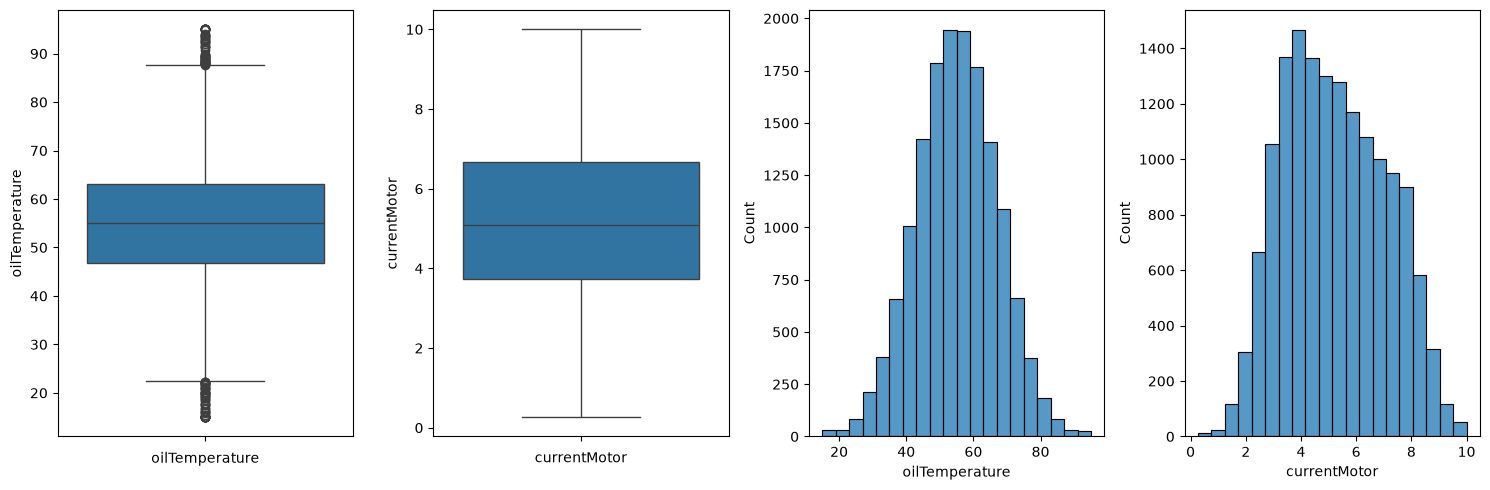

In [568]:
readings = readings.loc[
    readings["oilTemperature"].ne(-999)
    & readings["currentMotor"].ne(99)
].copy()

print(f"Difference in length after filtering oilTemperature and currentMotor: {len(tables['readings']) - len(readings)}")
tables["readings"] = readings

col_names = ["oilTemperature", "currentMotor"]

fig, ax = plt.subplots(1, len(col_names) * 2, figsize=(15, 5))

for i, col in enumerate(col_names):
    draw_boxplot(readings, col, ax[i])
    ax[i].set_xlabel(col)

for i, col in enumerate(col_names):
    sns.histplot(readings[col], bins=20, ax=ax[i + len(col_names)])
    ax[i + len(col_names)].set_xlabel(col)

plt.tight_layout()
plt.show()

### Findings and decisions

- **Identifiers:** Standardized `id_unit` to nullable `Int64` for matching across files while preserving missing values.
- **Relationships:** All 2,000 registered units have exactly one linked gateway and at least one reading. Repeated machine IDs in readings are expected.
- **Missing links:** Removed 162 orphan readings involving 134 IDs absent from the registry. Removed 14,000 gateways without a machine link, leaving 2,000 linked gateways. 
- **Dates:** Converted four formats in `cycleTs`, `installDate`, `lastSeen`, and `overhaulLast` to datetime with zero parsing failures. Supplied times were preserved; midnight for date-only values does not establish the measurement time.
- **Duty class:** Standardized 20 label variants into light (1), normal (2), and heavy (3), stored as nullable integers. All 2,000 records were mapped.
- **Duplicates:** Removed 230 exact copies from readings. Units and gateways contain no exact duplicates.
- **Labels:** Identical reading records, compared without `Failure` but including the timestamp, had consistent failure labels.
- **Operating hours:** Filled 100 missing `hours_service` values using the median for each commissioning year, supported by the strong correlation (r ≈ -0.993). No missing hours remain; filled values are estimates.
- **Sensor gaps:** Median-filled 640 `dpFilter`, 609 `rms_vibration`, and 769 `humidity_intake` values. Retained incomplete observations and preserved original availability using `_present` indicators; missing filter and vibration measurements were associated with higher failure rates. No sensor NaNs remain.
- **Sensor codes:** Removed 60 rows containing `oilTemperature = -999` or `currentMotor = 99`. The working dataset now contains 15,120 readings.
- **Outliers:** High `dpFilter` and `rms_vibration` readings were retained. Section 1.2 C compares removal and capping; boxplot outliers alone do not establish measurement errors.

## 1.2 B - Data correctness and consistency

In [569]:
installed_after_last_seen = gateways[gateways['installDate'] > gateways['lastSeen']]
print(f"Gateways with installDate after lastSeen: {len(installed_after_last_seen)}")
print("Failure rate for gateways with installDate after lastSeen: %.1f%%" % (readings.loc[readings['id_unit'].isin(installed_after_last_seen['id_unit']), 'Failure'].mean() * 100))
print("Failure rate for gateways without this date inconsistency: %.1f%%" % (readings.loc[~readings['id_unit'].isin(installed_after_last_seen['id_unit']), 'Failure'].mean() * 100))

units_with_overhaul_before_commission = units[units['year_commission'] > units['overhaulLast'].dt.year]
print(f"Units with overhaulLast before year_commission: {len(units_with_overhaul_before_commission)}")
print("Failure rate for units with overhaulLast before year_commission: %.1f%%" % (readings[readings['id_unit'].isin(units_with_overhaul_before_commission['id_unit'])]['Failure'].mean() * 100))
print("Failure rate for units without this overhaul inconsistency: %.1f%%" % (readings[~readings['id_unit'].isin(units_with_overhaul_before_commission['id_unit'])]['Failure'].mean() * 100))

Gateways with installDate after lastSeen: 100
Failure rate for gateways with installDate after lastSeen: 10.4%
Failure rate for gateways without this date inconsistency: 11.8%
Units with overhaulLast before year_commission: 1064
Failure rate for units with overhaulLast before year_commission: 10.1%
Failure rate for units without this overhaul inconsistency: 13.6%


In [570]:
checked = readings[["id_unit", "cycleTs", "Failure"]].merge(
    units[["id_unit", "year_commission"]],
    on="id_unit",
    how="left",
    validate="many_to_one",
)

before_commission = checked["cycleTs"].dt.year < checked["year_commission"]

print(f"Readings before commissioning year: {before_commission.sum()}")
print("Failure rate for readings before commissioning year: %.1f%%" % (checked.loc[before_commission, "Failure"].mean() * 100))
print("Failure rate for readings in or after commissioning year: %.1f%%" % (checked.loc[~before_commission, "Failure"].mean() * 100))

Readings before commissioning year: 324
Failure rate for readings before commissioning year: 4.9%
Failure rate for readings in or after commissioning year: 11.9%


These date checks cannot establish which value is wrong. Retain the readings and mark the inconsistent relationships.

**Integrate data and attach date flags**

In [571]:
integrated = readings.merge(
    units, on="id_unit", how="left", validate="many_to_one"
).merge(
    gateways,
    on="id_unit",
    how="left",
    validate="many_to_one",
    suffixes=("_unit", "_gateway"),
)

date_flags = pd.DataFrame({
    "gateway_dates_inconsistent": (
        integrated["installDate"].dt.normalize()
        > integrated["lastSeen"].dt.normalize()
    ),
    "overhaul_before_commission": (
        integrated["overhaulLast"].dt.year < integrated["year_commission"]
    ),
    "reading_before_commission": (
        integrated["cycleTs"].dt.year < integrated["year_commission"]
    ),
}, index=integrated.index)

integrated[date_flags.columns] = date_flags
integrated["date_uncertain"] = date_flags.any(axis=1)

date_quality_summary = pd.DataFrame({
    "affected_readings": date_flags.sum(),
    "affected_units": [
        integrated.loc[mask, "id_unit"].nunique()
        for _, mask in date_flags.items()
    ],
})
display(date_quality_summary)
display(integrated[["id_unit", "cycleTs", *date_flags.columns, "date_uncertain"]].head())

any_date_issue = integrated["date_uncertain"]
print(f"Removing every flagged reading would discard {any_date_issue.sum():,} of {len(integrated):,} readings ({any_date_issue.mean():.1%}).")
print(f"Readings retained by our decision: {len(integrated):,}")
print(f"Failure rate in retained data: {integrated['Failure'].mean():.2%}")
print(f"Failure rate after hypothetical removal: {integrated.loc[~any_date_issue, 'Failure'].mean():.2%}")

,affected_readings,affected_units
gateway_dates_inconsistent,756,100
overhaul_before_commission,8009,1064
reading_before_commission,324,43


,id_unit,cycleTs,gateway_dates_inconsistent,overhaul_before_commission,reading_before_commission,date_uncertain
0,193,2023-08-27 06:29:00,False,True,False,True
1,757,2023-11-13 00:00:00,False,False,False,False
2,1997,2023-11-26 00:00:00,False,False,False,False
3,1633,2023-02-22 00:00:00,False,True,False,True
4,467,2023-01-23 03:45:00,False,True,False,True


Removing every flagged reading would discard 8,383 of 15,120 readings (55.4%).
Readings retained by our decision: 15,120
Failure rate in retained data: 11.77%
Failure rate after hypothetical removal: 13.67%


Check cross-file consistency and value ranges

In [572]:
consistency_checks = pd.Series({
    "Readings without unit metadata": integrated["year_commission"].isna().sum(),
    "Readings without gateway metadata": integrated["gatewayId"].isna().sum(),
    "Readings with mismatched depot IDs": (
        integrated["depot_id_unit"] != integrated["depot_id_gateway"]
    ).sum(),
    "Readings with Failure outside {0, 1}": (~readings["Failure"].isin([0, 1])).sum(),
    "Units with negative operating hours": (units["hours_service"] < 0).sum(),
    "Readings with humidity outside 0-100%": (~readings["humidity_intake"].between(0, 100)).sum(),
    "Gateways with latitude outside -90 to 90": (~gateways["Lat"].between(-90, 90)).sum(),
    "Gateways with longitude outside -180 to 180": (~gateways["Lon"].between(-180, 180)).sum(),
}, name="violations")
display(consistency_checks.to_frame())

,violations
Readings without unit metadata,0
Readings without gateway metadata,0
Readings with mismatched depot IDs,0
"Readings with Failure outside {0, 1}",0
Units with negative operating hours,0
Readings with humidity outside 0-100%,0
Gateways with latitude outside -90 to 90,0
Gateways with longitude outside -180 to 180,0


### Findings and decisions

- **Integration:** Joined readings, units, and gateways on `id_unit` using validated many-to-one left joins. All 15,120 readings have matching unit and gateway metadata, with no rows lost or multiplied. Depot IDs agree across files.
- **Gateway dates:** Found 100 gateways with `lastSeen` before `installDate`, affecting 756 readings. Preserved the original dates and marked `gateway_dates_inconsistent`; gateway-lifetime calculations for these records remain deferred.
- **Overhaul dates:** Found 1,064 units with `overhaulLast` before their commissioning year, affecting 8,009 readings. Marked `overhaul_before_commission`. The check cannot identify the incorrect field, and component reuse or a different meaning of commissioning could explain the relationship; maintenance-age calculations remain deferred.
- **Commissioning dates:** Found 324 readings from 43 units recorded before their commissioning year. Preserved the readings and marked `reading_before_commission`; machine-age calculations for these records remain deferred.
- **Audit flags:** Attached all three Boolean flags to `integrated`, together with `date_uncertain`, which is true when any date check is flagged. Unit and gateway flags repeat across their associated readings; the reading-level flag is evaluated separately for each observation. Feature selection will determine whether any flags are suitable predictors.
- **Retention:** Removed no additional readings in 1.2 B. Deleting every flagged row would discard 8,383 readings (55.4%). All 15,120 readings and original date values were retained because the checks do not establish which date is wrong or invalidate the sensor measurements.
- **Abnormal values:** The remaining checks found no invalid failure labels, negative operating hours, out-of-range humidity or coordinates, missing metadata links, or depot mismatches. Sensor codes and duplicate-label consistency were addressed in 1.2 A.
- **Failure-rate comparisons:** Readings before commissioning have a 4.9% failure rate, compared with 11.9% for the remaining readings. Removing every date-flagged row would change the overall failure rate from 11.77% to 13.67%. These comparisons describe the selection effects of deletion; they do not determine which dates are correct.

## 1.2 C - Outlier detection and treatment

Compare row removal and capping on separate copies of the joined data. Estimate IQR boundaries from originally observed measurements.

In [573]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

sensor_columns = ["dpFilter", "rms_vibration"]
bounds = {}
outlier_flags = pd.DataFrame(index=integrated.index)

for column in sensor_columns:
    present = integrated[column + "_present"]
    lower, upper = iqr_bounds(integrated.loc[present, column])
    bounds[column] = {"lower": lower, "upper": upper}
    outlier_flags[column] = present & ~integrated[column].between(lower, upper)

bounds = pd.DataFrame(bounds).T
display(bounds.round(3))

,lower,upper
dpFilter,-2.042,46.982
rms_vibration,-0.848,6.546


In [574]:
rows = []
for column in sensor_columns:
    present = integrated[column + "_present"]
    groups = {
        "Observed outlier": outlier_flags[column],
        "Observed within bounds": present & ~outlier_flags[column],
        "Missing/imputed": ~present,
    }
    for group, mask in groups.items():
        failures = integrated.loc[mask, "Failure"]
        rows.append({
            "attribute": column,
            "group": group,
            "readings": len(failures),
            "failures": failures.sum(),
            "failure_rate_pct": failures.mean() * 100,
        })

failure_comparison = pd.DataFrame(rows).set_index(["attribute", "group"])
display(failure_comparison.round(2))

readings  failures  failure_rate_pct
attribute     group                                                       
dpFilter      Observed outlier             654       130             19.88
              Observed within bounds     13829      1300              9.40
              Missing/imputed              637       350             54.95
rms_vibration Observed outlier             586        70             11.95
              Observed within bounds     13927      1385              9.94
              Missing/imputed              607       325             53.54

Failure-rate comparisons separate observed measurements from missing/imputed values so the groups remain interpretable.

In [575]:
any_outlier = outlier_flags.any(axis=1)
removed_outliers = integrated.loc[~any_outlier].copy()
capped_outliers = integrated.copy()

for column in sensor_columns:
    capped_outliers[column] = capped_outliers[column].clip(
        lower=bounds.loc[column, "lower"],
        upper=bounds.loc[column, "upper"],
    )

variants = {
    "Original": integrated,
    "Removal": removed_outliers,
    "Capping": capped_outliers,
}
rows = []
for name, data in variants.items():
    changed_values = data[sensor_columns].ne(
        integrated.loc[data.index, sensor_columns]
    ).sum().sum()
    rows.append({
        "method": name,
        "readings": len(data),
        "removed_readings": len(integrated) - len(data),
        "failures": data["Failure"].sum(),
        "removed_failures": integrated["Failure"].sum() - data["Failure"].sum(),
        "failure_rate_pct": data["Failure"].mean() * 100,
        "modified_values": changed_values,
    })

method_comparison = pd.DataFrame(rows).set_index("method")
display(method_comparison.round(2))

,readings,removed_readings,failures,removed_failures,failure_rate_pct,modified_values
method,,,,,,
Original,15120,0,1780,0,11.77,0
Removal,13902,1218,1587,193,11.42,0
Capping,15120,0,1780,0,11.77,1240


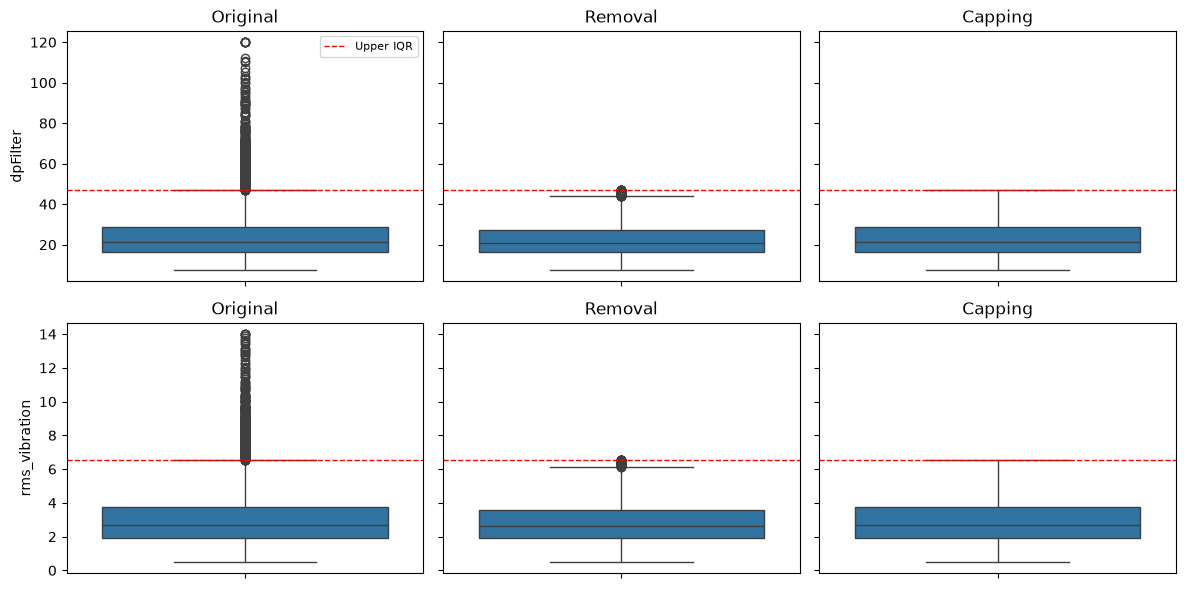

In [576]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey="row")

for j, (name, data) in enumerate(variants.items()):
    for i, column in enumerate(sensor_columns):
        ax = axes[i, j]
        sns.boxplot(
            y=data.loc[data[column + "_present"], column],
            ax=ax,
        )
        ax.axhline(
            bounds.loc[column, "upper"],
            color="red",
            linestyle="--",
            linewidth=1,
            label="Upper IQR",
        )
        ax.set_title(name)

axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Findings and decisions

- **Detection:** Calculated IQR boundaries from originally observed measurements. The upper boundaries are 46.982 for `dpFilter` and 6.546 for `rms_vibration`; all flagged observations are in the upper tails.
- **Filter readings:** Flagged 654 observations. Their failure rate is 19.88%, compared with 9.40% among observed readings within the boundaries. This supports retaining potentially informative high filter measurements.
- **Vibration readings:** Flagged 586 observations. Their failure rate is 11.95%, compared with 9.94% within the boundaries. The observed difference is modest; predictive usefulness is not established by this comparison alone.
- **Missing measurements:** Excluded imputed values from threshold estimation and observed-group comparisons. Reported missing/imputed measurements separately and preserved availability indicators in each dataset variant.
- **Removal:** Removing a complete reading when either sensor is outside its boundaries discards 1,218 readings (8.1%) and 193 failures (10.8% of all failures). The resulting dataset contains 13,902 readings; retained features and labels remain aligned.
- **Capping:** Applied the same boundaries on a separate copy, retaining all 15,120 readings and modifying 1,240 sensor values. This preserves rows and labels but compresses differences between extreme measurements.
- **Decision:** Retain both sensors and their original extreme values in `integrated`. The checks do not establish measurement errors, and the extremes may carry failure information. These are descriptive associations, with weaker evidence for vibration; repeated readings from the same unit are not independent.

## 1.3 - Statistical verification of hypotheses

### First hypothesis - Operating hours

Units with at least one observed failure have higher mean operating hours than units without an observed failure.

$H_0$: Their mean operating hours are equal or lower. \
$H_1$: Their mean operating hours are higher.


In [577]:
unit_outcomes = integrated.groupby("id_unit", as_index=False).agg(
    observed_failure=("Failure", "max"),
    reading_count=("Failure", "size"),
)

original_hours = original_units[["id_unit", "hours_service"]]

hypothesis_1 = unit_outcomes.merge(
    original_hours,
    on="id_unit",
    how="left",
    validate="one_to_one",
).dropna(subset=["hours_service"])

hypothesis_1.groupby("observed_failure").agg(
    units=("id_unit", "size"),
    mean_hours=("hours_service", "mean"),
    median_hours=("hours_service", "median"),
    std_hours=("hours_service", "std"),
    mean_readings=("reading_count", "mean"),
)

,units,mean_hours,median_hours,std_hours,mean_readings
observed_failure,,,,,
0,861,11927.748432,10106.8,7147.608152,6.872242
1,1039,15899.351588,13667.3,9258.203677,8.189605


In [578]:
failure_hours = hypothesis_1.loc[
    hypothesis_1["observed_failure"] == 1, "hours_service"
]
no_failure_hours = hypothesis_1.loc[
    hypothesis_1["observed_failure"] == 0, "hours_service"
]

result = stats.ttest_ind(
    failure_hours,
    no_failure_hours,
    equal_var=False,
    alternative="greater",
)

difference = failure_hours.mean() - no_failure_hours.mean()
lower_bound = result.confidence_interval(confidence_level=0.95).low

print(f"Mean difference: {difference:.1f} hours")
print(f"t-statistic: {result.statistic:.3f}")
print(f"p-value: {result.pvalue:.3e}")

if result.pvalue < 0.05:
    print("Reject the null hypothesis: units with failures have significantly higher operating hours.")
else:
    print("Fail to reject the null hypothesis: no significant difference in operating hours between units with and without failures.")

Mean difference: 3971.6 hours
t-statistic: 10.546
p-value: 1.322e-25
Reject the null hypothesis: units with failures have significantly higher operating hours.


### Second hypothesis - Duty class

The proportion of units with at least one observed failure differs between light, normal and heavy duty classes.

$H_0$: The failure proportions are equal across all three duty classes. \
$H_1$: At least one duty class has a different failure proportion.

observed_failure,No observed failure,Observed failure
duty_class,,
Light,236,561
Normal,347,345
Heavy,324,187


duty_class
Light     70.39
Normal    49.86
Heavy     36.59
Name: Failure rate (%), dtype: float64

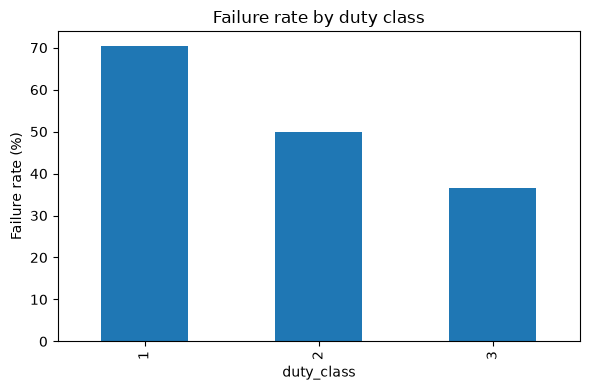

In [579]:
hypothesis_2 = unit_outcomes.merge(
    units[["id_unit", "duty_class"]],
    on="id_unit",
    how="left",
    validate="one_to_one",
)

duty_table = pd.crosstab(
    hypothesis_2["duty_class"],
    hypothesis_2["observed_failure"],
)

duty_names = {1: "Light", 2: "Normal", 3: "Heavy"}

display(duty_table.rename(
    index=duty_names,
    columns={0: "No observed failure", 1: "Observed failure"},
))

failure_pct = 100 * duty_table[1] / duty_table.sum(axis=1)
display(
    failure_pct.rename(index=duty_names)
    .rename("Failure rate (%)")
    .round(2)
)

fig, ax = plt.subplots(figsize=(6, 4))
failure_pct.plot.bar(
    ax=ax,
    ylabel="Failure rate (%)",
    title="Failure rate by duty class",
)
plt.tight_layout()
plt.show()

In [580]:
chi2_h2, p_h2, dof_h2, expected_h2 = stats.chi2_contingency(
    duty_table,
    correction=False,
)

print(f"Chi-square statistic: {chi2_h2:.3f}")
print(f"Degrees of freedom: {dof_h2}")
print(f"p-value: {p_h2:.3e}")
print(f"Minimum expected count: {expected_h2.min():.1f}")

if p_h2 < 0.05:
    print("Reject the null hypothesis: at least one duty class has a different proportion of units with observed failure.")
else:
    print("Fail to the reject null hypothesis: insufficient evidence that the proportions differ between duty classes.")

Chi-square statistic: 153.292
Degrees of freedom: 2
p-value: 5.166e-34
Minimum expected count: 231.7
Reject the null hypothesis: at least one duty class has a different proportion of units with observed failure.


- Operating hours: units with observed failures average 3,971.6 more hours, with p ≈ 1.32 × 10⁻²⁵.
- Duty class: the proportions of units with observed failures are 70.39% light, 49.86% normal and 36.59% heavy. The chi-square test supports an association.

## 1.3 B - Statistical power (operating hours)

Estimate the power of the first, one-sided Welch test for an assumed 1,000-hour mean difference at $\alpha = 0.05$. Reuse its degrees of freedom and the two groups' estimated variances. The target power is 80%.


In [581]:
alpha = 0.05
assumed_difference = 1000

se = np.sqrt(
    failure_hours.var(ddof=1) / len(failure_hours)
    + no_failure_hours.var(ddof=1) / len(no_failure_hours)
)
critical_t = stats.t.isf(alpha, result.df)
power = stats.nct.sf(critical_t, result.df, assumed_difference / se)

print(f"Assumed mean difference: {assumed_difference:,} hours")
print(f"Approximate power: {power:.1%} (target: 80%)")


Assumed mean difference: 1,000 hours
Approximate power: 84.4% (target: 80%)


Approximate power is **84.4%**, above the 80% target. The sample therefore has sufficient power for the assumed 1,000-hour difference, given independent units and the estimated variances. The 1,000-hour reference is illustrative.


### Findings and decisions

- **Operating hours:** The one-sided Welch test rejects $H_0$ ($p ≈ 1.32 × 10^{-25}$). Units with at least one observed failure average 3,971.6 more operating hours.
- **Duty class:** The chi-square test rejects $H_0$ ($p ≈ 5.17 × 10^{34}$). The proportions of units with observed failures are 70.39% for light, 49.86% for normal, and 36.59% for heavy duty.
- **Power:** For the first hypothesis, approximate power is 84.4% for an assumed 1,000-hour mean difference at α = 0.05, exceeding the 80% target.
- **Interpretation:** Both tests use one observation per unit and describe associations in the observed records. Different numbers of readings per unit can influence whether a failure is observed.
- **Decision:** Keep `hours_service` and `duty_class` as candidate predictors and assess their predictive value during feature selection and model validation.
